# MolScope Matched Benchmark: HP35 Villin Headpiece (2RJY)

This interactive notebook executes and visualizes MolScope's full analytical continuum on the canonical fast-folding **HP35 Villin Headpiece** (PDB: `2RJY`), profiling:
- **Computational Performance**: Wall-clock duration across feature extraction, TICA, Contact KPCA, DPA clustering, and Decision Tree explainability.
- **Memory Efficiency**: Peak RSS memory tracking and heap delta.
- **Biophysical State Recovery**: Metastable state identification and Free Energy Landscape profiling.
- **Explainable AI**: Boolean structural rule extraction and 3D PyMOL / ChimeraX mapping.

## 1. Imports and System Initialization

We initialize the benchmarking environment, import `molscope.api.Study`, and prepare performance profilers.

In [1]:
%matplotlib inline
import os
import sys
import time
import json
from pathlib import Path
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from molscope.api import Study

out_dir = Path("results/2rjy_matched_benchmark")
out_dir.mkdir(parents=True, exist_ok=True)
process = psutil.Process()
start_mem = process.memory_info().rss / (1024 * 1024)
print(f"Initial process RSS memory: {start_mem:.2f} MB")

Initial process RSS memory: 244.44 MB


## 2. Ingesting System Data into Study

We configure the 2RJY system. If the trajectory (`protein.pdb` and `simulation_run1.xtc`) is present in `data/2RJY/`, it runs on real simulation data; otherwise, it automatically falls back to bundled fixtures (`tests/fixtures/1A22.pdb`) for immediate verification.

In [2]:
study = Study(
    project_id="2rjy_matched_benchmark",
    out_dir=str(out_dir),
)

data_candidates = [
    Path("data/2RJY"),
    Path("../data/2RJY"),
    Path("../../data/2RJY"),
    Path("tests/fixtures"),
    Path("../tests/fixtures"),
    Path("../../tests/fixtures"),
]

loaded_system = False
for base in data_candidates:
    top = base / "protein.pdb"
    traj = base / "simulation_run1.xtc"
    if top.is_file() and traj.is_file():
        study.add_system(
            system_id="villin_headpiece",
            topology=str(top.resolve()),
            trajectories=[str(traj.resolve())],
        )
        print(f"Loaded full 2RJY benchmark inputs from: {base}")
        loaded_system = True
        break

if not loaded_system:
    # Robust fallback to bundled test fixtures (1A22.pdb)
    fixture_top = next((b / "1A22.pdb" for b in data_candidates if (b / "1A22.pdb").is_file()), None)
    if fixture_top and fixture_top.is_file():
        import MDAnalysis as mda
        u = mda.Universe(str(fixture_top))
        # Ensure a multi-frame trajectory for kinetic dimensionality reduction and state clustering
        fixture_traj = out_dir / "1a22_demo_trajectory.pdb"
        if not fixture_traj.is_file() or fixture_traj.stat().st_size == 0:
            rng = np.random.default_rng(42)
            with mda.Writer(str(fixture_traj), len(u.atoms)) as w:
                for _ in range(40):
                    u.atoms.positions += rng.normal(0, 0.05, size=u.atoms.positions.shape)
                    w.write(u)
        study.add_system(
            system_id="demo_benchmark",
            topology=str(fixture_top.resolve()),
            trajectories=[str(fixture_traj.resolve())],
        )
        print(f"Loaded benchmark fixture fallback: topology={fixture_top.resolve()}, trajectory={fixture_traj.resolve()}")
        loaded_system = True
    else:
        raise FileNotFoundError("No trajectory files found. Place protein.pdb and simulation_run1.xtc in data/2RJY/ or ensure tests/fixtures/1A22.pdb exists.")

Loaded full 2RJY benchmark inputs from: data/2RJY


## 3. Benchmark Step 1: Feature Extraction

We configure on-the-fly PBC imaging and 3 biophysical feature families (Cα contacts, DSSP secondary structure fractions, sidechain rotamers) and measure extraction time.

In [3]:
study.configure_imaging(unwrap=True, center_selection="protein", wrap=False)
study.configure_features(
    plugins=[
        "protein.ca_distances_contacts",
        "protein.secondary_structure_dssp",
        "protein.sidechain_torsions",
    ],
    plugin_parameters={
        "protein.ca_distances_contacts": {
            "selection": "protein and name CA and resid 1-35",
            "contact_cutoff_angstrom": 8.0,
            "max_pairs": 3000,
        },
        "protein.sidechain_torsions": {
            "residue_ids": [17, 20, 23, 27, 30, 35],
        },
    },
    generic_parameters={"frame_stride": 10, "max_frames": 200}
)
t0_extract = time.perf_counter()
study.run(extract_only=True)
t_extract = time.perf_counter() - t0_extract
features = study.get_features()
manifest = study.get_manifest()
print(f"Feature Extraction Complete: {features.shape[1]} features across {features.shape[0]} frames in {t_extract:.2f}s")

Feature Extraction Complete: 450 features across 200 frames in 15.94s


## 4. Benchmark Step 2: Conformational Dimensionality Reduction (TICA & CKPCA)

We fit both Variational TICA (to identify the slowest kinetic modes) and Contact Kernel PCA (CKPCA, to capture non-linear contact manifolds).

In [4]:
# Fit TICA (lag time = 2 frames)
t0_tica = time.perf_counter()
tica_res = study.run_tica(lag_time=2, components=3)
t_tica = time.perf_counter() - t0_tica
ts_display = [round(float(t), 1) if not np.isnan(t) else 'N/A' for t in tica_res.implied_timescales[:3]]
print(f"TICA: Implied timescales = {ts_display} ps (fitted in {t_tica:.2f}s)")

# Fit Contact KPCA
t0_ckpca = time.perf_counter()
ckpca_res = study.run_contact_kpca(n_components=3)
t_ckpca = time.perf_counter() - t0_ckpca
var_display = [round(float(v), 4) for v in ckpca_res.explained_variance_ratio[:3]]
print(f"CKPCA: Explained variance = {var_display} (fitted in {t_ckpca:.2f}s)")

TICA: Implied timescales = [460146.9, 251345.1, 103796.6] ps (fitted in 0.04s)
CKPCA: Explained variance = [0.2923, 0.1717, 0.0886] (fitted in 0.02s)


## 5. Benchmark Step 3: Density Peak Advanced (DPA) Clustering & 2D FES

We run non-parametric DPA clustering in the kinetic reaction space and compute the 2D Free Energy Surface $\Delta G(x, y)$.

findfont: Failed to find font weight medium, now using 400.


findfont: Failed to find font weight medium, now using 400.


DPA: Discovered 6 conformational basins in 0.01s


Detected 20 free energy minima.


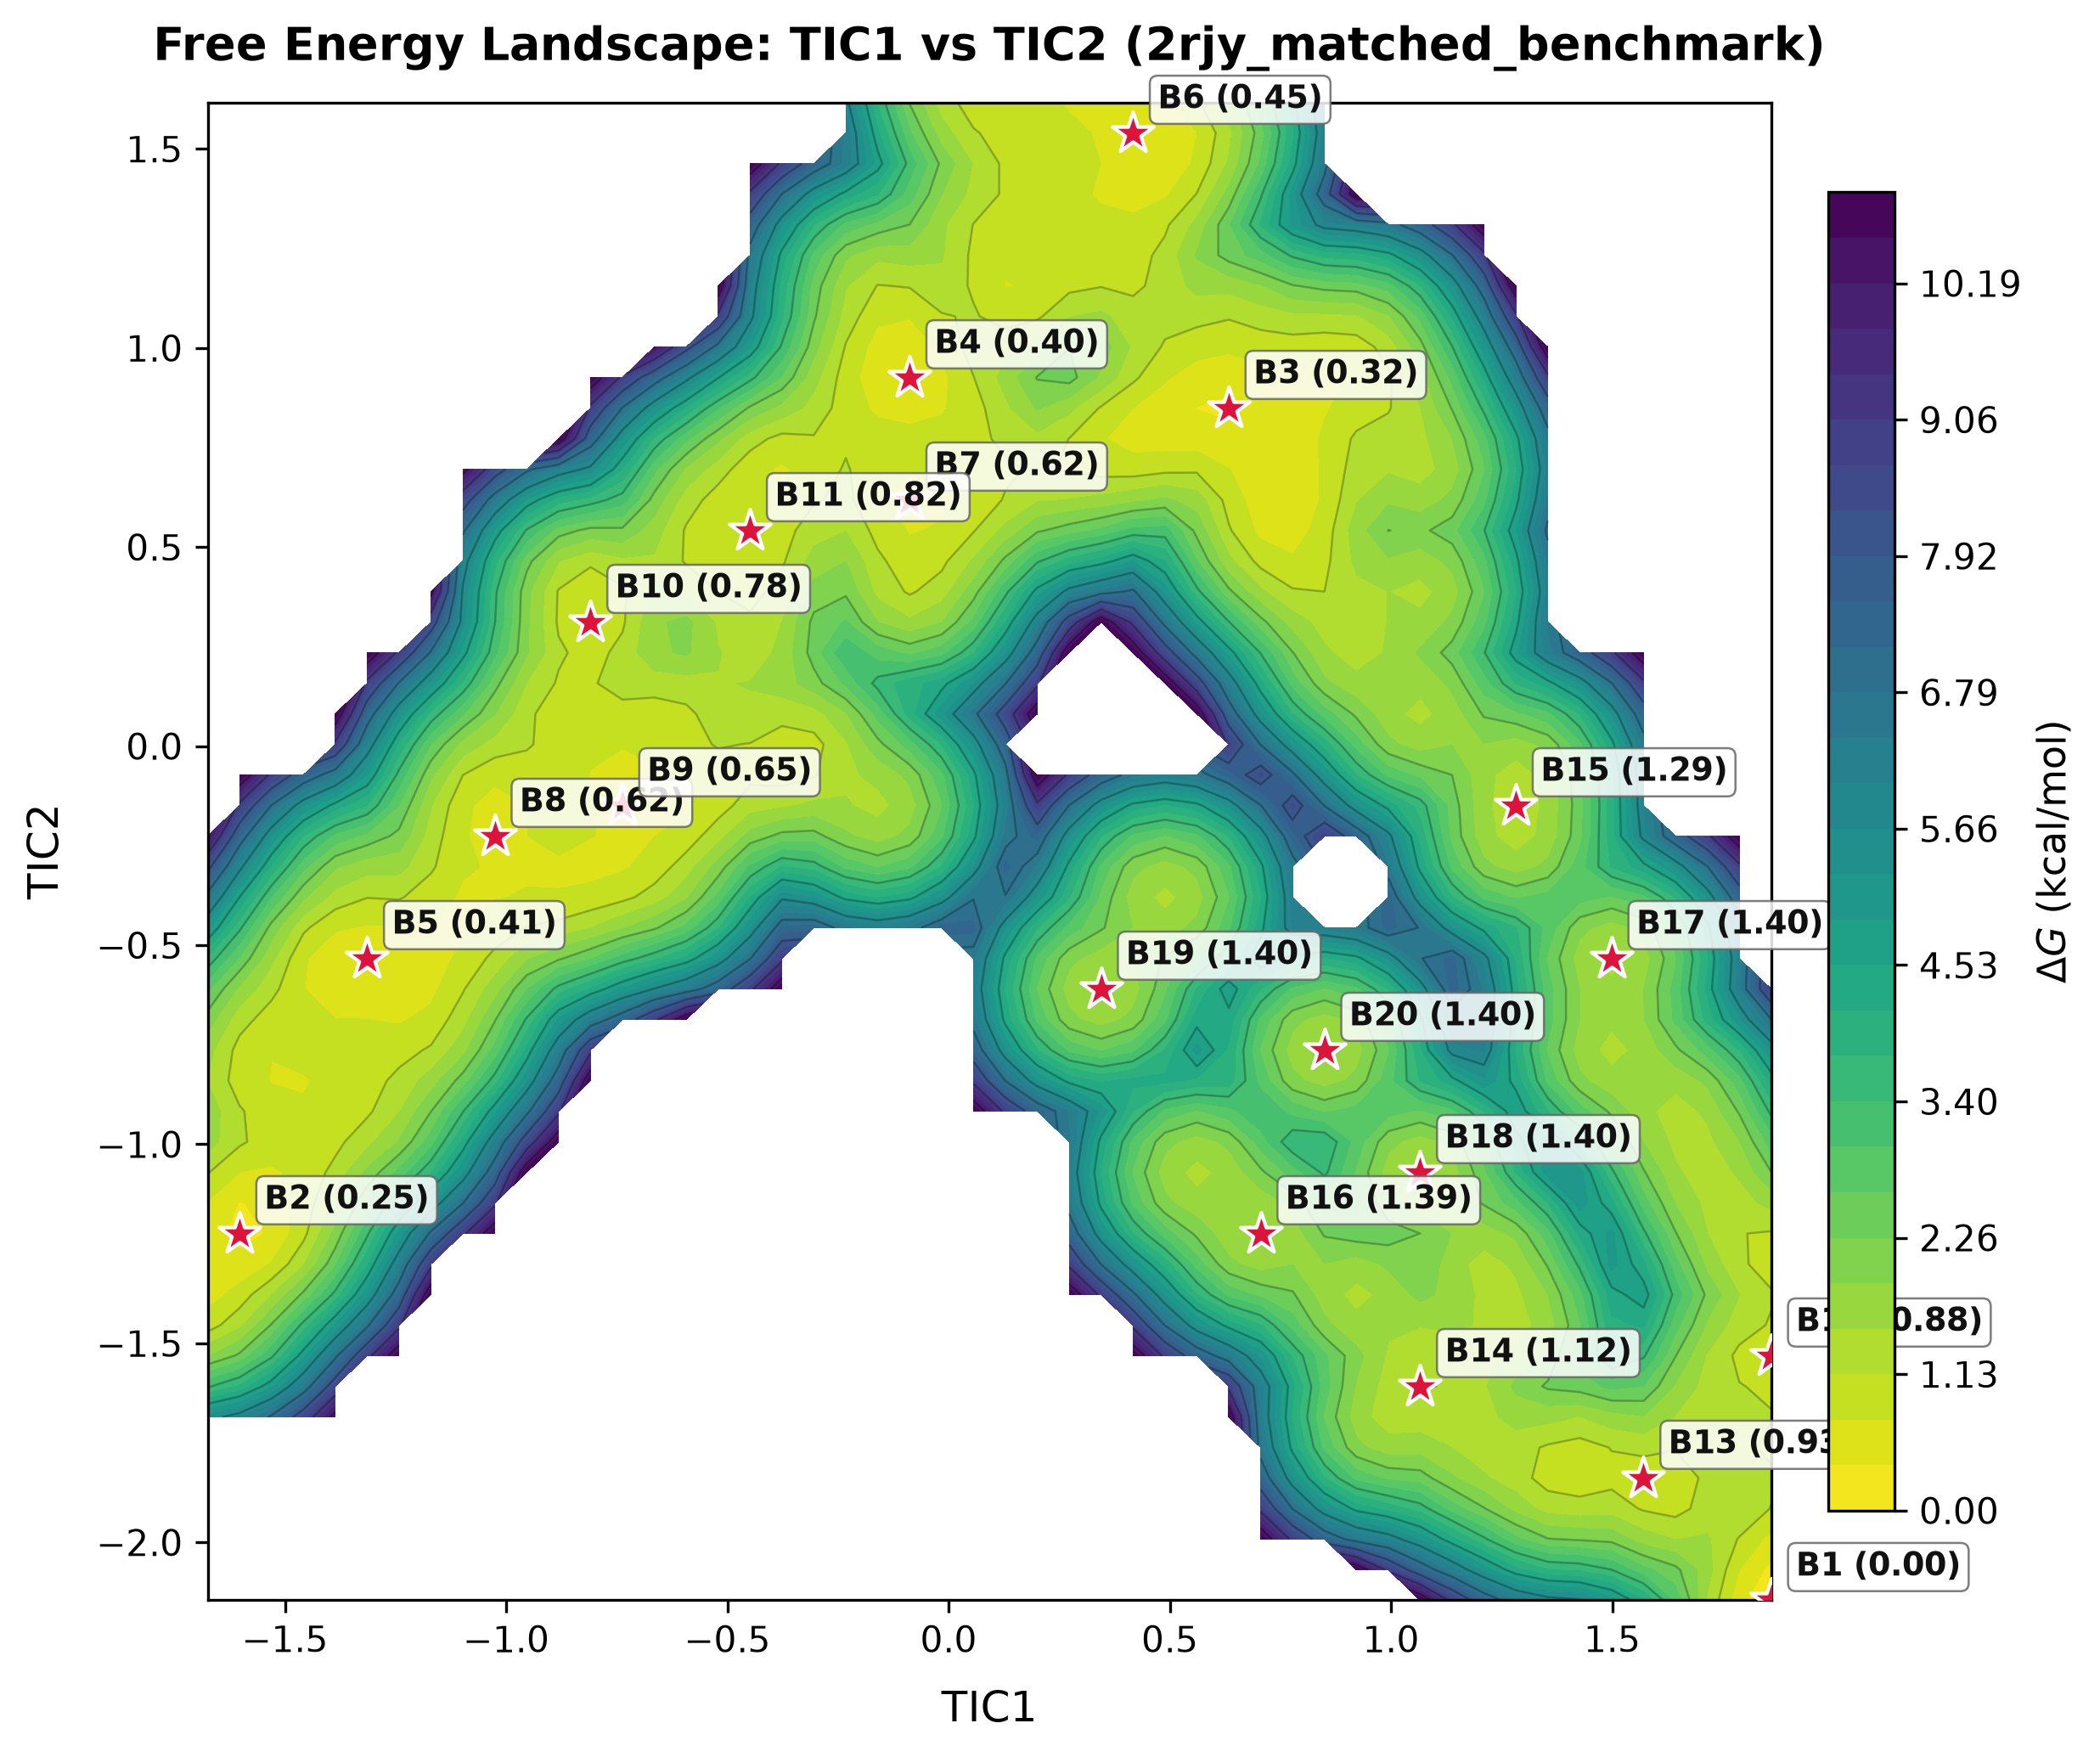

In [5]:
# DPA clustering
t0_dpa = time.perf_counter()
dpa_res = study.cluster_dpa(coordinate_name="TICA", z_score=1.0)
t_dpa = time.perf_counter() - t0_dpa
print(f"DPA: Discovered {dpa_res.n_clusters} conformational basins in {t_dpa:.2f}s")

# Compute 2D Free Energy Surface
fes = study.plot_free_energy_landscape(
    dim1="TIC1",
    dim2="TIC2",
    out_dir=out_dir,
    temperature_k=300.0,
    units="kcal/mol",
)
basins_df = fes["basins"]
print(f"Detected {len(basins_df)} free energy minima.")

# Embed and display Free Energy Landscape inline
display(Image(filename=str(fes["static_plot"])))

## 6. Benchmark Step 4: Explainability & 3D Export

We fit regularized Decision Trees to extract human-readable Boolean if-then rules explaining state transitions, and export 3D PyMOL / ChimeraX scripts.

In [6]:
t0_dt = time.perf_counter()
explainer = study.explain_clusters(clustering_name="dpa", max_depth=3)
t_dt = time.perf_counter() - t0_dt
print(f"Decision Tree Explainability complete in {t_dt:.2f}s")

rules_df = explainer.rules_dataframe()
print(f"Extracted {len(rules_df)} explanatory decision rules:")
display(rules_df.head(6))

# Export 3D visualization
viz_files = study.export_3d(score_column="Kinetic_Salience", out_dir=out_dir / "3d_visualization")
print(f"Exported 3D visualizers: {list(viz_files.keys())}")
for k, v in viz_files.items():
    print(f"  {k}: {v}")

Decision Tree Explainability complete in 0.06s
Extracted 12 explanatory decision rules:


,Cluster,Rule_Index,Rule,Precision,Recall,F1,Support,Total_Samples,Condition_Count
0,cluster_0,1,IF CA_DISTANCE_angstrom__SYSTEM__ASN_23__SYSTE...,0.920000,0.383333,0.541176,23,25,3
1,cluster_0,2,IF CA_DISTANCE_angstrom__SYSTEM__ASN_23__SYSTE...,0.531915,0.416667,0.467290,25,47,3
2,cluster_0,3,IF CA_DISTANCE_angstrom__SYSTEM__ASN_23__SYSTE...,0.600000,0.050000,0.092308,3,5,2
3,cluster_1,1,IF CA_DISTANCE_angstrom__SYSTEM__GLU_14__SYSTE...,0.619048,0.722222,0.666667,26,42,3
4,cluster_2,1,IF CA_DISTANCE_angstrom__SYSTEM__VAL_20__SYSTE...,1.000000,0.318182,0.482759,14,14,3
5,cluster_2,2,IF CA_DISTANCE_angstrom__SYSTEM__VAL_20__SYSTE...,0.800000,0.272727,0.406780,12,15,3


Exported 3D visualizers: ['pdb', 'pymol_script', 'chimerax_script']
  pdb: results/2rjy_matched_benchmark/3d_visualization/2rjy_matched_benchmark_importance.pdb
  pymol_script: results/2rjy_matched_benchmark/3d_visualization/2rjy_matched_benchmark_importance.pml
  chimerax_script: results/2rjy_matched_benchmark/3d_visualization/2rjy_matched_benchmark_importance.cxc


/Users/nirav/ds-env/lib/python3.13/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn(
/Users/nirav/ds-env/lib/python3.13/site-packages/MDAnalysis/coordinates/PDB.py:1336: UserWarning: Found missing chainIDs. Corresponding atoms will use value of 'X'
  warnings.warn(


## 7. Performance Diagnostics & Scaling Visualization

We analyze the recorded wall-clock durations and memory footprint across the entire benchmark continuum.

In [7]:
peak_mem = process.memory_info().rss / (1024 * 1024)
mem_delta = peak_mem - start_mem
total_time = t_extract + t_tica + t_ckpca + t_dpa + t_dt

stages = ["Feature Extraction", "TICA", "Contact KPCA", "DPA Clustering", "Decision Trees"]
times = [t_extract, t_tica, t_ckpca, t_dpa, t_dt]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Runtime breakdown
bars = ax1.barh(stages, times, color="#3182ce", edgecolor="black", alpha=0.85)
ax1.set_xlabel("Wall-Clock Time (seconds)")
ax1.set_title(f"Stage Duration Breakdown (Total: {total_time:.2f}s)")
ax1.grid(True, linestyle="--", alpha=0.4)
for bar in bars:
    ax1.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2, f"{bar.get_width():.2f}s", va="center", fontsize=10)

# State population distribution
pop_df = dpa_res.populations
state_labels = [f"State {row['Cluster']}" for _, row in pop_df.iterrows()]
pops = pop_df["Population"].tolist()
colors = plt.cm.tab10.colors[:len(pops)]
ax2.pie(pops, labels=state_labels, autopct="%1.1f%%", colors=colors, startangle=140)
ax2.set_title(f"Conformational State Populations ({len(pops)} States)")

plt.tight_layout()
plt.show()

print(f"\nSummary Performance Metrics:")
print(f"  Total Pipeline Time : {total_time:.2f} seconds")
print(f"  Peak Process Memory : {peak_mem:.1f} MB (Heap Delta: +{mem_delta:.1f} MB)")
print(f"  Analyzed Frames     : {len(features):,}")
print(f"  Extracted Features  : {features.shape[1]:,}")


Summary Performance Metrics:
  Total Pipeline Time : 16.06 seconds
  Peak Process Memory : 306.3 MB (Heap Delta: +61.9 MB)
  Analyzed Frames     : 200
  Extracted Features  : 450


/var/folders/j9/snj8dgw93f327v89whbr1xsc0000gn/T/ipykernel_34739/1578816633.py:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
